## TH 5.1

Dựng tam giác Pascal $10$ hàng trong ma trận số nguyên $10\times10$ bằng *slicing* (mỗi hàng tính từ hàng trước bằng một phép cộng vector, không dùng vòng lặp lồng): $P_{i,j}=P_{i-1,j}+P_{i-1,j-1}$, $P_{i,0}=1$. In hàng $4$ và hàng $9$; kiểm tra $\binom94=126$ và tổng hàng $9$ bằng $2^9$.

In [1]:
import numpy as np
from math import comb

n = 10
P = np.zeros((n, n), dtype=int)
P[:, 0] = 1                                 
for i in range(1, n):                        
    P[i, 1:] = P[i-1, 1:] + P[i-1, :-1]      

print("Hàng 4:", P[4, :5])                  
print("Hàng 9:", P[9])                      

print(P[9, 4] == 126, P[9, 4] == comb(9, 4))   
print(P[9].sum() == 2**9)                      

Hàng 4: [1 4 6 4 1]
Hàng 9: [  1   9  36  84 126 126  84  36   9   1]
True True
True


## TH 5.5

Ma trận $N=\begin{pmatrix}0&1&2
0&0&3
0&0&0\end{pmatrix}$ thoả $N^3=0$ (luỹ linh). Kiểm tra bằng NumPy: (i) $N^3=0$; (ii) $(I-N)^{-1}=I+N+N^2$; (iii) $(I+N)^{-1}=I-N+N^2$. Giải thích đẳng thức (ii) bằng nhân hai vế với $(I-N)$.

In [2]:
N = np.array([[0, 1, 2],
              [0, 0, 3],
              [0, 0, 0]])
I = np.eye(3)

print(np.allclose(np.linalg.matrix_power(N, 3), 0))                 
print(np.allclose(np.linalg.inv(I - N), I + N + N @ N))             
print(np.allclose(np.linalg.inv(I + N), I - N + N @ N))             

True
True
True


## TH 5.6

Cho $A=\begin{pmatrix}2&1&-1&0
1&3&2&1
0&-1&4&2
3&0&1&5\end{pmatrix}$ và véc tơ nghiệm biết trước $\mathbf x^*=(1,-1,2,3)^\top$. Đặt $\mathbf b=A\mathbf x^*$, giải lại hệ bằng `np.linalg.solve`, kiểm chứng bằng `np.allclose`. Sau đó thay hàng $4$ của $A$ bằng tổng hàng $1$ và hàng $2$ và ghi lại lỗi của `solve`.

In [3]:
A = np.array([[2,  1, -1, 0],
              [1,  3,  2, 1],
              [0, -1,  4, 2],
              [3,  0,  1, 5]], dtype=float)
x_star = np.array([1, -1, 2, 3], dtype=float)
b = A @ x_star                                

x = np.linalg.solve(A, b)
print(x, np.allclose(x, x_star))              
print(np.allclose(A @ x, b))                  

A2 = A.copy()
A2[3] = A[0] + A[1]                           

try:
    np.linalg.solve(A2, b)
except np.linalg.LinAlgError as e:
    print("Lỗi:", e)                          

[ 1. -1.  2.  3.] True
True


## TH 5.7

Đa thức bậc $3$ đi qua bốn điểm $(0,1)$, $(1,0)$, $(2,5)$, $(3,22)$ là duy nhất. Tìm các hệ số $c_0,…,c_3$ của $p(x)=c_0+c_1x+c_2x^2+c_3x^3$ bằng cách giải hệ với *ma trận Vandermonde* (`np.vander(x, increasing=True)`), kiểm tra bằng `allclose`, rồi tính $p(1{,}5)$.

In [4]:
import numpy as np

x = np.array([0, 1, 2, 3], dtype=float)
y = np.array([1, 0, 5, 22], dtype=float)

V = np.vander(x, increasing=True)     
c = np.linalg.solve(V, y)             
print("Hệ số:", c)                    

print(np.allclose(V @ c, y))          

p = lambda t: c[0] + c[1]*t + c[2]*t**2 + c[3]*t**3
print("p(1.5) =", p(1.5))            

Hệ số: [ 1.00000000e+00 -2.00000000e+00 -1.33226763e-15  1.00000000e+00]
True
p(1.5) = 1.3749999999999982


## TH 5.8

Với ma trận ngẫu nhiên $500\times500$ (`default_rng(0)`) và véc tơ $\mathbf b$ ngẫu nhiên, giải $A\mathbf x=\mathbf b$ bằng `solve` và bằng `inv(A) @ b`. So sánh *phần dư* $\|A\mathbf x-\mathbf b\|$ và thời gian của hai cách; kiểm tra bằng `assert` cả hai nghiệm đều đạt phần dư rất nhỏ và giống nhau.

In [6]:
import numpy as np
import time

rng = np.random.default_rng(0)
n = 500
A = rng.standard_normal((n, n))
b = rng.standard_normal(n)

t0 = time.perf_counter()
x1 = np.linalg.solve(A, b)
t_solve = time.perf_counter() - t0

t0 = time.perf_counter()
x2 = np.linalg.inv(A) @ b
t_inv = time.perf_counter() - t0

r1 = np.linalg.norm(A @ x1 - b)
r2 = np.linalg.norm(A @ x2 - b)

print(f"solve : residual = {r1:.2e}, time = {t_solve*1e3:.2f} ms")
print(f"inv@b : residual = {r2:.2e}, time = {t_inv*1e3:.2f} ms")

solve : residual = 1.58e-11, time = 6.62 ms
inv@b : residual = 1.76e-11, time = 18.17 ms


## TH 6.2

Viết chương trình nhập danh sách sinh viên (họ tên, mã sinh viên, ngày sinh dạng `dd/mm/yyyy`) từ bàn phím, dừng khi người dùng bỏ trống họ tên (vòng `while True`, Chương \ref{ch:dieukhien}). Lưu vào một `DataFrame`, chuyển ngày sinh sang kiểu thời gian bằng `pd.to_datetime(…, format="%d/%m/%Y")`, tính cột `Tuoi` (số năm nguyên) từ ngày sinh đến mốc $01/01/2026$ (dùng `pd.Timestamp("2026-01-01")`, chia số ngày cho $365{,}25$ rồi lấy phần nguyên), ghi ra `students.xlsx` bằng `to_excel` (cần `openpyxl`) và đọc lại để kiểm tra. Dùng mốc cố định thay cho `pd.Timestamp.now()` để kết quả tái lập được.

In [7]:
import pandas as pd

rows = []
while True:
    ho_ten = input("Họ tên (bỏ trống để dừng): ").strip()
    if ho_ten == "":
        break
    ma_sv = input("Mã sinh viên: ").strip()
    ngay_sinh = input("Ngày sinh (dd/mm/yyyy): ").strip()
    rows.append({"HoTen": ho_ten, "MaSV": ma_sv, "NgaySinh": ngay_sinh})

df = pd.DataFrame(rows, columns=["HoTen", "MaSV", "NgaySinh"])

df["NgaySinh"] = pd.to_datetime(df["NgaySinh"], format="%d/%m/%Y")

moc = pd.Timestamp("2026-01-01")
df["Tuoi"] = ((moc - df["NgaySinh"]).dt.days / 365.25).astype(int)
print(df)

df.to_excel("students.xlsx", index=False)
df2 = pd.read_excel("students.xlsx", dtype={"MaSV": str})   
print(df2)
print(df2.dtypes)

Họ tên (bỏ trống để dừng):  nguyễn văn a
Mã sinh viên:  1234512345
Ngày sinh (dd/mm/yyyy):  12/12/2000
Họ tên (bỏ trống để dừng):  nguyễn văn b
Mã sinh viên:  5432154321
Ngày sinh (dd/mm/yyyy):  23/3/2003
Họ tên (bỏ trống để dừng):  


          HoTen        MaSV   NgaySinh  Tuoi
0  nguyễn văn a  1234512345 2000-12-12    25
1  nguyễn văn b  5432154321 2003-03-23    22
          HoTen        MaSV   NgaySinh  Tuoi
0  nguyễn văn a  1234512345 2000-12-12    25
1  nguyễn văn b  5432154321 2003-03-23    22
HoTen                  str
MaSV                   str
NgaySinh    datetime64[us]
Tuoi                 int64
dtype: object


## TH 6.3

Với `data/200heightsweights.csv` (chiều cao inch, cân nặng pound của $200$ người): (1) đổi tên cột thành `Height_in`, `Weight_lb`, đổi sang cm và kg, điền ô thiếu bằng trung bình cột, tính `BMI`, viết bằng method chaining; (2) đếm số người có $\mathrm{BMI}<18{,}5$; (3) dùng `pd.cut` chia chiều cao thành ba nhóm: `Thap` ($<170$ cm), `Trung binh` ($[170,175)$), `Cao` ($\ge175$) và đếm số người từng nhóm; (4) dùng `groupby` tính *tỉ lệ* người có $\mathrm{BMI}<18{,}5$ trong từng nhóm (gợi ý: trung bình của một cột logic là tỉ lệ `True`); (5) vẽ boxplot cân nặng theo nhóm chiều cao bằng Seaborn và lưu `box.png`; (6) nếu đã cài `plotly`, vẽ biểu đồ phân tán tương tác chiều cao -- cân nặng, tô màu theo nhóm.

['Index', 'Height(Inches)', 'Weight(Pounds)']
   Index  Height_in  Weight_lb  Height_cm  Weight_kg        BMI
0      1      65.78     112.99   167.0812  51.251402  18.359066
1      2      71.52     136.49   181.6608  61.910823  18.760488
2      3      69.40     153.03   176.2760  69.413240  22.338600
3      4      68.22     142.34   173.2788  64.564338  21.503138
4      5      67.79     144.30   172.1866  65.453379  22.076660
Số người BMI < 18,5: 50
Nhom
Thap          62
Trung binh    81
Cao           57
Name: count, dtype: int64
Nhom
Thap          0.258065
Trung binh    0.234568
Cao           0.263158
Name: Thieu_can, dtype: float64


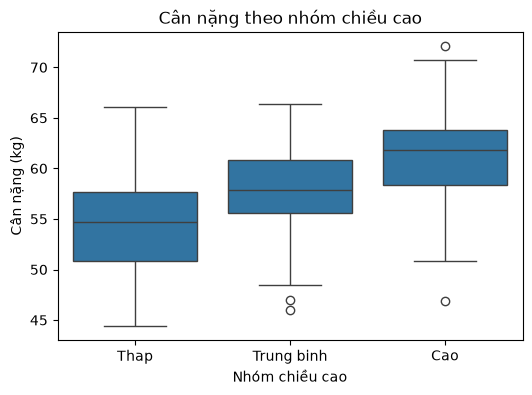

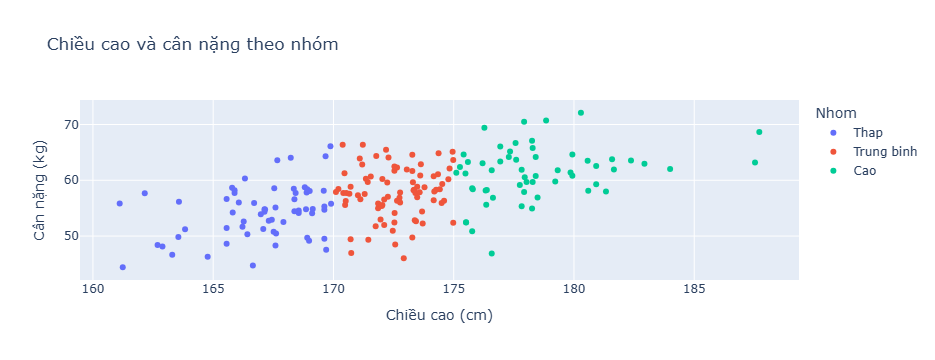

In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

raw = pd.read_csv("200heightsweights.csv")
print(raw.columns.tolist())                     
h_col, w_col = raw.columns[-2:]                 

df = (
    raw
    .rename(columns={h_col: "Height_in", w_col: "Weight_lb"})
    .assign(
        Height_in=lambda d: d["Height_in"].fillna(d["Height_in"].mean()),
        Weight_lb=lambda d: d["Weight_lb"].fillna(d["Weight_lb"].mean()),
    )
    .assign(
        Height_cm=lambda d: d["Height_in"] * 2.54,
        Weight_kg=lambda d: d["Weight_lb"] * 0.45359237,
    )
    .assign(BMI=lambda d: d["Weight_kg"] / (d["Height_cm"] / 100) ** 2)
)
print(df.head())

print("Số người BMI < 18,5:", (df["BMI"] < 18.5).sum())

labels = ["Thap", "Trung binh", "Cao"]
df["Nhom"] = pd.cut(
    df["Height_cm"],
    bins=[-np.inf, 170, 175, np.inf],
    labels=labels,
    right=False,                                
)
print(df["Nhom"].value_counts().reindex(labels))

ti_le = (
    df.assign(Thieu_can=df["BMI"] < 18.5)
      .groupby("Nhom", observed=True)["Thieu_can"]
      .mean()
)
print(ti_le)

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Nhom", y="Weight_kg", order=labels)
plt.xlabel("Nhóm chiều cao")
plt.ylabel("Cân nặng (kg)")
plt.title("Cân nặng theo nhóm chiều cao")
plt.savefig("box.png", dpi=150, bbox_inches="tight")
plt.show()

try:
    import plotly.express as px
    fig = px.scatter(
        df, x="Height_cm", y="Weight_kg", color="Nhom",
        category_orders={"Nhom": labels},
        labels={"Height_cm": "Chiều cao (cm)", "Weight_kg": "Cân nặng (kg)"},
        title="Chiều cao và cân nặng theo nhóm",
    )
    fig.show()
except ImportError:
    print("Chưa cài plotly: pip install plotly")